# Audio Classification — Barbie vs Puppy

This project classifies short audio recordings into two classes: **Barbie** and **Puppy**.

The workflow uses Librosa to load audio, preprocess the waveform, extract audio features, and train supervised classifiers. The original exercise explored MFCCs, spectral centroid, spectral rolloff, zero-crossing rate, Gaussian Naive Bayes, Logistic Regression, and a custom bagging ensemble.

> **Dataset required:** the original audio files were not included with the notebook. Place your `.wav` recordings in a folder and ensure each filename contains either `barbie` or `puppy` (case-insensitive). The notebook does not invent or replace the original audio dataset.

## 1. Install and import dependencies

In Google Colab, run the installation cell if the libraries are not already available. For local Jupyter, install dependencies using the repository's `requirements.txt`.

In [1]:
# Uncomment in Google Colab if needed:
# %pip install -q librosa soundfile

import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Set the dataset folder and inspect audio files

Set `DATA_DIR` to the folder containing the `.wav` recordings. In Colab, you can upload/extract the dataset and set this path to its folder. The expected labels are inferred from filenames containing `barbie` or `puppy`.

In [2]:
# Update this path to the folder containing your WAV files.
DATA_DIR = Path("audio_data")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR.resolve()}\\n"
        "Create the folder and add your WAV recordings, or update DATA_DIR."
    )

audio_paths = sorted(DATA_DIR.glob("*.wav"))
if not audio_paths:
    raise FileNotFoundError(f"No .wav files found in {DATA_DIR.resolve()}")

def label_from_filename(filename):
    name = filename.lower()
    if "puppy" in name:
        return 1
    if "barbie" in name:
        return 0
    raise ValueError(
        f"Cannot infer class from filename '{filename}'. "
        "Include 'barbie' or 'puppy' in each filename."
    )

records = []
for path in audio_paths:
    try:
        label = label_from_filename(path.name)
        records.append({"path": path, "filename": path.name, "label": label})
    except ValueError as exc:
        print("Skipping:", exc)

metadata = pd.DataFrame(records)
if metadata.empty:
    raise ValueError("No correctly labelled WAV files were found.")

display(metadata.head())
print("\\nClass counts:")
print(metadata["label"].map({0: "Barbie", 1: "Puppy"}).value_counts())

,path,filename,label
0,audio_data\barbie_0.wav,barbie_0.wav,0
1,audio_data\barbie_1.wav,barbie_1.wav,0
2,audio_data\barbie_10.wav,barbie_10.wav,0
3,audio_data\barbie_11.wav,barbie_11.wav,0
4,audio_data\barbie_12.wav,barbie_12.wav,0


\nClass counts:
label
Barbie    50
Puppy     48
Name: count, dtype: int64


## 3. Audio preprocessing and feature extraction

Each recording is loaded as mono audio at a common sample rate of 22,050 Hz. Silence is trimmed and the waveform is peak-normalized safely.

Features:
- Mean and standard deviation of 13 MFCC coefficients
- Mean spectral centroid
- Mean spectral rolloff
- Mean zero-crossing rate

Using the same feature extraction function for training recordings and new recordings keeps feature order consistent.

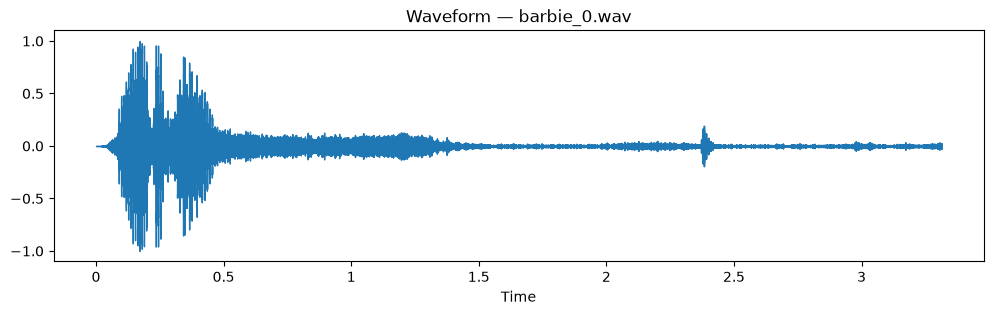

Feature vector shape: (29,)


In [3]:
TARGET_SR = 22050
N_MFCC = 13

def preprocess_audio(file_path, target_sr=TARGET_SR):
    y, sr = librosa.load(file_path, sr=target_sr, mono=True)
    y, _ = librosa.effects.trim(y)

    if y.size == 0:
        raise ValueError("Audio is empty after silence trimming.")

    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak

    return y, target_sr


def extract_features(y, sr=TARGET_SR):
    if y.size == 0:
        raise ValueError("Cannot extract features from empty audio.")

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(y)

    feature_vector = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        [np.mean(centroid)],
        [np.mean(rolloff)],
        [np.mean(zcr)]
    ])

    return feature_vector.astype(np.float64)

# Inspect one example waveform and its feature vector.
example_path = metadata.iloc[0]["path"]
example_audio, _ = preprocess_audio(example_path)

plt.figure(figsize=(12, 3))
librosa.display.waveshow(example_audio, sr=TARGET_SR)
plt.title(f"Waveform — {example_path.name}")
plt.xlabel("Time")
plt.show()

example_features = extract_features(example_audio)
print("Feature vector shape:", example_features.shape)

## 4. Build the feature dataset

The following cell extracts one feature vector per recording. Files that cannot be decoded or processed are reported and skipped.

In [4]:
feature_rows = []
failed_files = []

for row in metadata.itertuples(index=False):
    try:
        audio, sr = preprocess_audio(row.path)
        features = extract_features(audio, sr)
        feature_rows.append({
            "filename": row.filename,
            "label": row.label,
            **{f"feature_{i}": value for i, value in enumerate(features)}
        })
    except Exception as exc:
        failed_files.append((row.filename, str(exc)))

features_df = pd.DataFrame(feature_rows)
if features_df.empty:
    raise ValueError("Feature extraction failed for every audio file.")

if failed_files:
    print("Files skipped due to errors:")
    for filename, error in failed_files:
        print(f"- {filename}: {error}")

display(features_df.head())
print("Processed recordings:", len(features_df))
print("Feature count:", features_df.shape[1] - 2)

,filename,label,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28
0,barbie_0.wav,0,-288.745026,101.996452,15.255393,7.670107,23.814615,4.372325,-8.958282,5.038925,...,10.649713,11.730918,9.135950,7.053592,7.463592,7.566231,6.386290,2367.314809,4553.218388,0.140943
1,barbie_1.wav,0,-321.958160,98.595619,3.910542,15.839601,13.911185,2.532637,-3.399933,-2.147118,...,8.823872,6.634875,10.568604,7.362526,9.554029,6.919446,5.993201,2251.541017,4682.414246,0.121661
2,barbie_10.wav,0,-260.778473,160.997131,18.774691,28.926151,3.730768,2.755382,1.048461,3.478314,...,9.538645,10.840548,9.911102,9.036771,10.108494,7.181654,5.323593,962.644786,1707.708444,0.036038
3,barbie_11.wav,0,-296.428741,130.455063,12.500963,26.344589,3.762031,3.913729,-1.694579,-2.037657,...,9.090631,9.035801,8.212714,6.885978,9.241037,7.259519,5.412765,1331.273529,2707.960193,0.047547
4,barbie_12.wav,0,-337.824371,109.822243,-5.717292,42.345676,14.643671,-11.809934,1.523528,-5.141954,...,8.516829,10.150784,12.236779,7.435697,9.112163,16.337627,9.498624,1553.445103,3087.322998,0.081932


Processed recordings: 98
Feature count: 29


## 5. Prepare training and test sets

A stratified split preserves the class proportions. The test set is held out until final evaluation. Feature scaling is fitted on the training set only and is included inside the Logistic Regression pipeline to prevent data leakage.

In [5]:
feature_columns = [c for c in features_df.columns if c.startswith("feature_")]
X = features_df[feature_columns].to_numpy(dtype=float)
y = features_df["label"].to_numpy(dtype=int)

class_counts = pd.Series(y).value_counts()
if len(class_counts) != 2 or class_counts.min() < 2:
    raise ValueError(
        "At least two recordings per class are needed for a stratified train/test split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train class counts:", Counter(y_train))
print("Test class counts:", Counter(y_test))

Train shape: (73, 29)
Test shape: (25, 29)
Train class counts: Counter({np.int64(0): 37, np.int64(1): 36})
Test class counts: Counter({np.int64(0): 13, np.int64(1): 12})


## 6. Implement Gaussian Naive Bayes from scratch

The Gaussian Naive Bayes classifier estimates a mean, variance, and prior probability for each class. Predictions are made using log probabilities for numerical stability.

In [6]:
class GaussianNaiveBayes(ClassifierMixin, BaseEstimator):

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)
        self.means = {}
        self.variances = {}
        self.priors = {}

        for cls in self.classes_:
            X_cls = X[y == cls]

            self.means[cls] = X_cls.mean(axis=0)
            self.variances[cls] = X_cls.var(axis=0) + 1e-8
            self.priors[cls] = len(X_cls) / len(X)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = []

        for sample in X:
            log_posteriors = []

            for cls in self.classes_:
                mean = self.means[cls]
                var = self.variances[cls]

                log_likelihood = -0.5 * np.sum(
                    np.log(2 * np.pi * var)
                    + ((sample - mean) ** 2) / var
                )

                log_posteriors.append(
                    np.log(self.priors[cls]) + log_likelihood
                )

            predictions.append(
                self.classes_[np.argmax(log_posteriors)]
            )

        return np.asarray(predictions)

## 7. Train Logistic Regression

A StandardScaler is applied before Logistic Regression. This is important because the extracted audio features have different numeric ranges.

In [7]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)
)
logistic_model.fit(X_train, y_train)

nb_model = make_pipeline(
    StandardScaler(),
    GaussianNaiveBayes()
)
nb_model.fit(X_train, y_train)

predictions = {
    "Gaussian Naive Bayes": nb_model.predict(X_test),
    "Logistic Regression": logistic_model.predict(X_test)
}

## 8. Implement a Bagging ensemble

Bagging trains multiple base estimators on bootstrap samples and combines their predictions using majority voting. For Logistic Regression, each estimator includes its own StandardScaler pipeline.

In [8]:
class BaggingEnsemble:
    def __init__(self, estimator_factory, n_estimators=7, random_state=42):
        self.estimator_factory = estimator_factory
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.models = []

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self.models = []

        for _ in range(self.n_estimators):
            indices = rng.choice(len(X), size=len(X), replace=True)
            model = self.estimator_factory()
            model.fit(X[indices], y[indices])
            self.models.append(model)

        return self

    def predict(self, X):
        all_predictions = np.array([model.predict(X) for model in self.models])
        final_predictions = []
        for column in all_predictions.T:
            final_predictions.append(Counter(column).most_common(1)[0][0])
        return np.asarray(final_predictions)


bagged_nb = BaggingEnsemble(
    estimator_factory=GaussianNaiveBayes,
    n_estimators=7,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

bagged_lr = BaggingEnsemble(
    estimator_factory=lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)
    ),
    n_estimators=7,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

predictions["Bagged Gaussian Naive Bayes"] = bagged_nb.predict(X_test)
predictions["Bagged Logistic Regression"] = bagged_lr.predict(X_test)

## 9. Evaluate all models

Accuracy, precision, recall, and F1-score are reported for each model. The positive class is Puppy (`1`).

In [9]:
def evaluate_models(y_true, predictions_dict):
    rows = []
    for model_name, y_pred in predictions_dict.items():
        rows.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-score": f1_score(y_true, y_pred, zero_division=0)
        })
    return pd.DataFrame(rows).sort_values("F1-score", ascending=False)

results_df = evaluate_models(y_test, predictions)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
1,Logistic Regression,0.80,0.8182,0.75,0.7826
3,Bagged Logistic Regression,0.72,0.6923,0.75,0.7200
0,Gaussian Naive Bayes,0.60,0.6000,0.50,0.5455
2,Bagged Gaussian Naive Bayes,0.60,0.6000,0.50,0.5455


Best model on this test split: Logistic Regression
              precision    recall  f1-score   support

      Barbie       0.79      0.85      0.81        13
       Puppy       0.82      0.75      0.78        12

    accuracy                           0.80        25
   macro avg       0.80      0.80      0.80        25
weighted avg       0.80      0.80      0.80        25



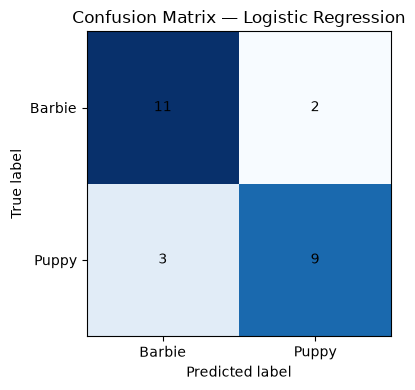

In [10]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

print("Best model on this test split:", best_model_name)
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Barbie", "Puppy"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], ["Barbie", "Puppy"])
plt.yticks([0, 1], ["Barbie", "Puppy"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## 10. Predict a new audio file

Use the same preprocessing and feature extraction functions for a new WAV recording. The selected model must be trained on the feature matrix created above.

Change `NEW_AUDIO_PATH` to a valid recording. The filename is not used to predict its class.

In [11]:
# Example:
# NEW_AUDIO_PATH = Path("audio_data/new_recording.wav")

def predict_audio_file(model, file_path):
    audio, sr = preprocess_audio(file_path)
    feature_vector = extract_features(audio, sr).reshape(1, -1)
    prediction = int(model.predict(feature_vector)[0])
    return "Puppy" if prediction == 1 else "Barbie"

# Use the trained Logistic Regression model as an example:
# print(predict_audio_file(logistic_model, NEW_AUDIO_PATH))

## 11. Optional: record from a microphone

Microphone recording is optional and may not work in hosted notebook environments. Install `sounddevice` and `scipy` locally if you want to use this feature. It is separate from the core training and evaluation workflow.

In [12]:
# Optional local-machine feature:
%pip install sounddevice scipy

import sounddevice as sd

def record_and_predict(model, duration=3, sr=TARGET_SR):
    recording = sd.rec(
        int(duration * sr), samplerate=sr, channels=1, dtype="float32"
    )
    sd.wait()
    audio = recording.flatten()
    audio, _ = librosa.effects.trim(audio)
    peak = np.max(np.abs(audio))
    if peak > 0:
        audio = audio / peak
    feature_vector = extract_features(audio, sr).reshape(1, -1)
    prediction = int(model.predict(feature_vector)[0])
    print("Prediction:", "Puppy" if prediction == 1 else "Barbie")
    return prediction

Note: you may need to restart the kernel to use updated packages.


In [16]:
record_and_predict(logistic_model)

Prediction: Puppy


1

## Conclusion and limitations

This project demonstrates an audio classification pipeline using hand-crafted audio features and supervised machine-learning models.

### Key points
- MFCCs capture timbral and spectral characteristics.
- Spectral centroid, spectral rolloff, and zero-crossing rate provide additional audio descriptors.
- Gaussian Naive Bayes and Logistic Regression provide baseline classifiers.
- Bagging combines multiple estimators through bootstrap sampling and majority voting.

### Limitations
- The dataset is small, so reported metrics can vary substantially with the train/test split.
- Filename-based labels require filenames to include `barbie` or `puppy`.
- Trimming silence is not spectral noise reduction; the original notebook's `reduce_noise` function only trimmed leading and trailing silence.
- The model should be evaluated on more recordings and with cross-validation before making strong claims about generalization.